In [19]:
import sys
from pathlib import Path
import pandas as pd

# project root = the folder that contains `src`, wherever the kernel was started
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt

from src.data.loader import load_cub, class_names
from src.data.prepare import prepare_splits
from src.data.loaders import build_dataloaders
from src.models.factory import build_classifier

## 1. Data

`load_cub` downloads (first run) or reads the cached CUB train and test splits. `prepare_splits` cleans the captions and carves the stratified validation set out of train. `build_dataloaders` wraps each split: train is augmented and shuffled, validation and test only get the deterministic resize and center crop.

In [9]:
raw = load_cub()  # default Hugging Face cache; pass cache_dir="data/hf_cache" to use the project folder
data = prepare_splits(raw["train"], raw["test"], val_fraction=0.15, seed=42)
print(data)

DatasetDict({
    train: Dataset({
        features: ['image', 'description', 'label', 'file_name', 'id', 'captions'],
        num_rows: 5094
    })
    validation: Dataset({
        features: ['image', 'description', 'label', 'file_name', 'id', 'captions'],
        num_rows: 900
    })
    test: Dataset({
        features: ['image', 'description', 'label', 'file_name', 'id', 'captions'],
        num_rows: 5794
    })
})


In [10]:
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

loaders = build_dataloaders(data, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)
species = class_names(data["train"])

for name, loader in loaders.items():
    print(f"{name:10s} {len(loader.dataset):5d} images, {len(loader):3d} batches of {BATCH_SIZE}")
print("species:", len(species))

train       5094 images, 160 batches of 32
validation   900 images,  29 batches of 32
test        5794 images, 182 batches of 32
species: 200


In [11]:
images, labels = next(iter(loaders["train"]))
print("images:", tuple(images.shape), images.dtype)
print("labels:", tuple(labels.shape), labels.dtype, "| first five:", [species[i] for i in labels[:5]])

images: (32, 3, 224, 224) torch.float32
labels: (32,) torch.int64 | first five: ['Philadelphia Vireo', 'Gray Catbird', 'Black and white Warbler', 'Florida Jay', 'White Pelican']


In [12]:
model = build_classifier()

In [13]:
from torchinfo import summary

summary(
    model,
    input_size=(BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE),
    col_names=("input_size", "output_size", "num_params", "kernel_size"),
    depth=3,
    col_width=18,
)

Layer (type:depth-idx)                        Input Shape        Output Shape       Param #            Kernel Shape
BirdClassifier                                [32, 3, 224, 224]  [32, 200]          --                 --
├─ScratchEncoder: 1-1                         [32, 3, 224, 224]  [32, 32, 112, 112] --                 --
│    └─Sequential: 2-1                        [32, 3, 224, 224]  [32, 32, 112, 112] --                 --
│    │    └─Conv2d: 3-1                       [32, 3, 224, 224]  [32, 32, 112, 112] 864                [3, 3]
│    │    └─BatchNorm2d: 3-2                  [32, 32, 112, 112] [32, 32, 112, 112] 64                 --
│    │    └─ReLU: 3-3                         [32, 32, 112, 112] [32, 32, 112, 112] --                 --
│    └─ModuleList: 2-2                        --                 --                 --                 --
│    │    └─ResidualBlock: 3-4                [32, 32, 112, 112] [32, 64, 56, 56]   57,728             --
│    │    └─ResidualBlock: 3-5  

## 2. Training setup

Adam optimizer and cross-entropy loss. The loss takes raw logits, so the model has no softmax layer.

In [14]:
import time
import copy

import numpy as np
from torch import nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

LR = 1e-3
EPOCHS = 10

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)  # same starting weights every run
model = build_classifier().to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

device: mps


In [15]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    """One pass over the train loader with weight updates. Returns (mean loss, accuracy)."""
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += len(labels)
    return total_loss / seen, correct / seen


@torch.inference_mode()
def evaluate(model, loader, loss_fn, device):
    """One pass without weight updates (and without dropout or batch statistics updates)."""
    model.eval()
    total_loss, top5_correct, seen = 0.0, 0, 0
    all_labels, all_predictions = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)

        total_loss += loss_fn(logits, labels).item() * len(labels)
        top5_correct += (logits.topk(k=5, dim=1).indices == labels[:, None]).any(dim=1).sum().item()
        seen += len(labels)
        all_labels.append(labels.cpu())
        all_predictions.append(logits.argmax(dim=1).cpu())

    labels = torch.cat(all_labels).numpy()
    predictions = torch.cat(all_predictions).numpy()
    return {
        "loss": total_loss / seen,
        "accuracy": float((labels == predictions).mean()),
        "top5_accuracy": top5_correct / seen,
        "labels": labels,
        "predictions": predictions,
    }

## 3. Train

Every epoch: one pass over train, then one evaluation on validation. The weights of the epoch with the best validation accuracy are kept. Test is not touched until the end.

In [16]:
history = []
best_val_accuracy, best_state, best_epoch = -1.0, None, 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss, train_accuracy = train_one_epoch(model, loaders["train"], loss_fn, optimizer, device)
    val = evaluate(model, loaders["validation"], loss_fn, device)

    history.append({"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy,
                    "val_loss": val["loss"], "val_accuracy": val["accuracy"]})

    if val["accuracy"] > best_val_accuracy:
        best_val_accuracy, best_epoch = val["accuracy"], epoch
        best_state = copy.deepcopy(model.state_dict())

    print(f"epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.3f} acc {train_accuracy:.3f} | "
          f"val loss {val['loss']:.3f} acc {val['accuracy']:.3f} | {time.time() - start:.0f}s")

print(f"best validation accuracy {best_val_accuracy:.3f} at epoch {best_epoch}")

epoch  1/10 | train loss 5.312 acc 0.010 | val loss 5.050 acc 0.021 | 20s
epoch  2/10 | train loss 5.036 acc 0.019 | val loss 4.939 acc 0.029 | 15s
epoch  3/10 | train loss 4.928 acc 0.024 | val loss 4.835 acc 0.038 | 15s
epoch  4/10 | train loss 4.827 acc 0.036 | val loss 4.777 acc 0.049 | 15s
epoch  5/10 | train loss 4.756 acc 0.039 | val loss 4.729 acc 0.048 | 15s
epoch  6/10 | train loss 4.681 acc 0.041 | val loss 4.647 acc 0.042 | 15s
epoch  7/10 | train loss 4.573 acc 0.054 | val loss 4.651 acc 0.051 | 16s
epoch  8/10 | train loss 4.498 acc 0.059 | val loss 4.445 acc 0.078 | 16s
epoch  9/10 | train loss 4.382 acc 0.068 | val loss 4.387 acc 0.081 | 16s
epoch 10/10 | train loss 4.295 acc 0.077 | val loss 4.356 acc 0.072 | 15s
best validation accuracy 0.081 at epoch 9


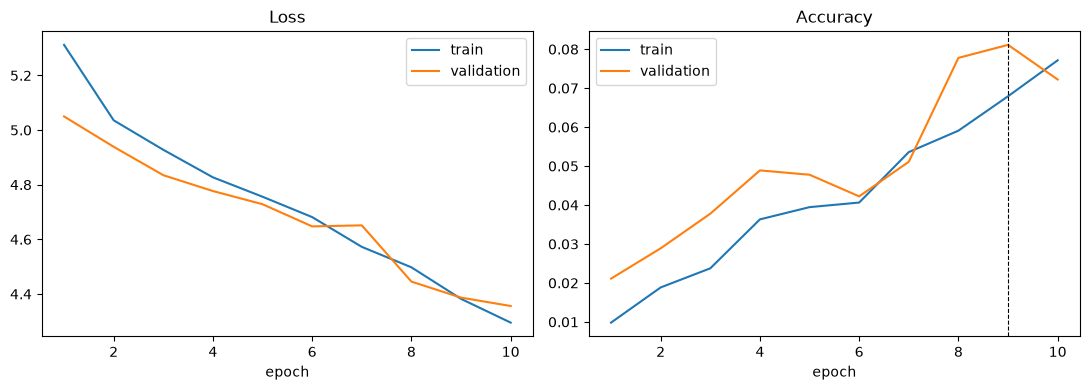

In [17]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, [h["train_loss"] for h in history], label="train")
axes[0].plot(epochs, [h["val_loss"] for h in history], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(epochs, [h["train_accuracy"] for h in history], label="train")
axes[1].plot(epochs, [h["val_accuracy"] for h in history], label="validation")
axes[1].axvline(best_epoch, ls="--", c="k", lw=0.8)
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Evaluate

The best-validation weights are loaded, then validation and test are evaluated once each.

In [20]:
model.load_state_dict(best_state)

rows = {}
for name in ("validation", "test"):
    result = evaluate(model, loaders[name], loss_fn, device)
    labels, predictions = result["labels"], result["predictions"]
    rows[name] = {
        "loss": result["loss"],
        "accuracy": accuracy_score(labels, predictions),
        "top-5 accuracy": result["top5_accuracy"],
        "precision (macro)": precision_score(labels, predictions, average="macro", zero_division=0),
        "recall (macro)": recall_score(labels, predictions, average="macro", zero_division=0),
        "F1 (macro)": f1_score(labels, predictions, average="macro", zero_division=0),
    }

pd.DataFrame(rows).round(4)

,validation,test
loss,4.3867,4.3985
accuracy,0.0811,0.0690
top-5 accuracy,0.2289,0.2271
precision (macro),0.0600,0.0667
recall (macro),0.0818,0.0705
F1 (macro),0.0548,0.0507
